In [1]:
#Import the required libraries
import numpy as np
import pandas as pd
import tensorflow as tf

#Step1: Preparing the parent folder for custom training and child folder to store the data

In [3]:

import os
import zipfile
import pandas as pd
import shutil
from sklearn.model_selection import train_test_split

# -------- CONFIG --------
images_zip_path = "Images.zip"
labels_path = "labels.csv"
extract_path = "raw_images"
output_path = "vehicle_dataset"
# ------------------------

# Clean old folders
if os.path.exists(extract_path):
    shutil.rmtree(extract_path)
if os.path.exists(output_path):
    shutil.rmtree(output_path)

os.makedirs(extract_path, exist_ok=True)
os.makedirs(output_path, exist_ok=True)

# Extract images
with zipfile.ZipFile(images_zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

images_base_path = os.path.join(extract_path, "Images")

# Load labels
labels_df = pd.read_csv(labels_path, header=None)
labels_df.columns = ["image_id", "class", "x1", "y1", "x2", "y2"]

# Keep only existing images
existing_images = set([int(f.split(".")[0]) for f in os.listdir(images_base_path)])
filtered_df = labels_df[labels_df["image_id"].isin(existing_images)]

# Take first label per image
image_class_df = filtered_df.groupby("image_id").first().reset_index()

# Train-test split
train_df, test_df = train_test_split(image_class_df, test_size=0.2, random_state=42)

# Organize dataset
def organize_dataset(df, subset):
    for _, row in df.iterrows():
        image_name = f"{str(row['image_id']).zfill(8)}.jpg"
        class_name = row["class"]

        src = os.path.join(images_base_path, image_name)
        dst_dir = os.path.join(output_path, subset, class_name)
        os.makedirs(dst_dir, exist_ok=True)

        if os.path.exists(src):
            shutil.copy(src, os.path.join(dst_dir, image_name))

organize_dataset(train_df, "train")
organize_dataset(test_df, "test")

print("Dataset successfully created!")

Dataset successfully created!


#Reducing the no. of child folder to reduce the imbalance in dataset

In [4]:
import os
import shutil

# Define your new grouping
class_mapping = {
    "car": "car",
    "pickup_truck": "truck",
    "articulated_truck": "truck",
    "truck": "truck",
    "bus": "bus",
    "van": "car",
    "motorcycle": "two_wheeler",
    "bicycle": "two_wheeler"
}

old_dataset = "vehicle_dataset"
new_dataset = "vehicle_dataset_reduced"

if os.path.exists(new_dataset):
    shutil.rmtree(new_dataset)

for subset in ["train", "test"]:
    for old_class in os.listdir(os.path.join(old_dataset, subset)):

        if old_class not in class_mapping:
            continue

        new_class = class_mapping[old_class]

        src_dir = os.path.join(old_dataset, subset, old_class)
        dst_dir = os.path.join(new_dataset, subset, new_class)

        os.makedirs(dst_dir, exist_ok=True)

        for file in os.listdir(src_dir):
            shutil.copy(
                os.path.join(src_dir, file),
                os.path.join(dst_dir, file)
            )

print("New reduced dataset created!")

New reduced dataset created!


#Step 2: Preparing the data for model training

In [5]:
#Prepocessing the image for making data compatible for CNN
train_generator=tf.keras.preprocessing.image.ImageDataGenerator(rescale=1.0/255.0)
test_generator=tf.keras.preprocessing.image.ImageDataGenerator(rescale=1.0/255.0)

In [7]:
trainimagedata=train_generator.flow_from_directory('vehicle_dataset_reduced/train',
                                                   batch_size=20,
                                                   class_mode='categorical',
                                                   target_size=(224,224))
testimagedata=test_generator.flow_from_directory('vehicle_dataset_reduced/test',
                                                   batch_size=20,
                                                   class_mode='categorical',
                                                   target_size=(224,224))

Found 3922 images belonging to 4 classes.
Found 992 images belonging to 4 classes.


#Step 3: Creating our custom model for CNN architecture

In [37]:
#Create our custom model
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.optimizers import Adam

num_classes = 4

base_model = MobileNetV2(
    weights='imagenet',
    include_top=False,   # IMPORTANT
    input_shape=(224,224,3)
)

base_model.trainable = False  # Freeze base

x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dropout(0.4)(x)
x = Dense(128, activation='relu')(x)
x = Dropout(0.4)(x)
output = Dense(num_classes, activation='softmax')(x)

model = Model(inputs=base_model.input, outputs=output)

model.compile(
    optimizer=Adam(learning_rate=0.0001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 112, 112,  │        864 │ input_layer_2[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 112, 112,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 112, 112,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 112, 112,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 112, 112,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 112, 112,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 113, 113,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 56, 56,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 56, 56,    │      2,304 │ block_1_depthwis

 Total params: 2,422,468 (9.24 MB)

 Trainable params: 164,484 (642.52 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

#Step 4:Compile and Evaluating the model

In [13]:
model.compile(tf.keras.optimizers.Adam(learning_rate=0.0001),
              loss="categorical_crossentropy",
              metrics=['accuracy','f1_score'])

In [15]:
model.fit(trainimagedata,
          validation_data=testimagedata,
          epochs=10,
          steps_per_epoch=int(len(trainimagedata.filenames) / trainimagedata.batch_size),
          validation_steps=int(len(testimagedata.filenames) / testimagedata.batch_size)
          )

Epoch 1/10
196/196 ━━━━━━━━━━━━━━━━━━━━ 29s 148ms/step - accuracy: 0.6127 - f1_score: 0.2446 - loss: 1.0805 - val_accuracy: 0.7092 - val_f1_score: 0.2162 - val_loss: 0.7480
Epoch 2/10
  1/196 ━━━━━━━━━━━━━━━━━━━━ 4s 24ms/step - accuracy: 0.8000 - f1_score: 0.2222 - loss: 0.6879

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:116: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


196/196 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.8000 - f1_score: 0.2222 - loss: 0.6879 - val_accuracy: 0.7122 - val_f1_score: 0.2168 - val_loss: 0.7433
Epoch 3/10
196/196 ━━━━━━━━━━━━━━━━━━━━ 12s 59ms/step - accuracy: 0.7002 - f1_score: 0.2685 - loss: 0.8117 - val_accuracy: 0.7102 - val_f1_score: 0.2099 - val_loss: 0.7146
Epoch 4/10
196/196 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.6000 - f1_score: 0.1935 - loss: 1.0498 - val_accuracy: 0.7102 - val_f1_score: 0.2099 - val_loss: 0.7117
Epoch 5/10
196/196 ━━━━━━━━━━━━━━━━━━━━ 19s 64ms/step - accuracy: 0.7136 - f1_score: 0.2821 - loss: 0.7694 - val_accuracy: 0.7112 - val_f1_score: 0.2328 - val_loss: 0.7025
Epoch 6/10
196/196 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.7000 - f1_score: 0.2656 - loss: 0.6562 - val_accuracy: 0.7133 - val_f1_score: 0.2332 - val_loss: 0.6997
Epoch 7/10
196/196 ━━━━━━━━━━━━━━━━━━━━ 12s 59ms/step - accuracy: 0.7182 - f1_score: 0.2777 - loss: 0.7096 - val_accuracy: 0.7153 - val_f1_score: 0.2758 -

#Finetuning Experiment to increase the F1 score and get more generalized model

In [18]:
#Unfreeze last 20 layers
base_model.trainable = True

for layer in base_model.layers[:-20]:
    layer.trainable = False

In [21]:
#Very low learning rate
from tensorflow.keras.optimizers import Adam

model.compile(
    optimizer=Adam(1e-5),
    loss='categorical_crossentropy',
    metrics=['accuracy','f1_score'])


In [22]:
model.fit(trainimagedata,
          validation_data=testimagedata,
          epochs=10,
          steps_per_epoch=int(len(trainimagedata.filenames) / trainimagedata.batch_size),
          validation_steps=int(len(testimagedata.filenames) / testimagedata.batch_size)
          )

Epoch 1/10
196/196 ━━━━━━━━━━━━━━━━━━━━ 38s 121ms/step - accuracy: 0.7485 - f1_score: 0.3426 - loss: 0.6089 - val_accuracy: 0.7398 - val_f1_score: 0.4003 - val_loss: 0.6122
Epoch 2/10
196/196 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - accuracy: 0.6500 - f1_score: 0.3000 - loss: 0.8434 - val_accuracy: 0.7418 - val_f1_score: 0.4040 - val_loss: 0.6042
Epoch 3/10
196/196 ━━━━━━━━━━━━━━━━━━━━ 19s 58ms/step - accuracy: 0.7608 - f1_score: 0.4151 - loss: 0.5822 - val_accuracy: 0.7449 - val_f1_score: 0.4188 - val_loss: 0.6042
Epoch 4/10
196/196 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.8000 - f1_score: 0.3039 - loss: 0.4767 - val_accuracy: 0.7429 - val_f1_score: 0.4173 - val_loss: 0.5999
Epoch 5/10
196/196 ━━━━━━━━━━━━━━━━━━━━ 12s 60ms/step - accuracy: 0.7588 - f1_score: 0.4165 - loss: 0.5808 - val_accuracy: 0.7459 - val_f1_score: 0.4279 - val_loss: 0.5962
Epoch 6/10
196/196 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.6500 - f1_score: 0.3185 - loss: 0.9586 - val_accuracy: 0.7449 - val_f1_sco

In [24]:
#Fine tuning further to get more performance from the model
base_model.trainable = True

for layer in base_model.layers[:-20]:
    layer.trainable = False

In [25]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-5),
    loss='categorical_crossentropy',
    metrics=['accuracy','f1_score']
)

In [27]:
model.fit(trainimagedata,
          validation_data=testimagedata,
          epochs=20,
          steps_per_epoch=int(len(trainimagedata.filenames) / trainimagedata.batch_size),
          validation_steps=int(len(testimagedata.filenames) / testimagedata.batch_size)
          )

Epoch 1/20
196/196 ━━━━━━━━━━━━━━━━━━━━ 12s 60ms/step - accuracy: 0.7985 - f1_score: 0.6004 - loss: 0.4839 - val_accuracy: 0.7449 - val_f1_score: 0.4786 - val_loss: 0.5751
Epoch 2/20
196/196 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.9000 - f1_score: 0.6103 - loss: 0.3596 - val_accuracy: 0.7469 - val_f1_score: 0.4829 - val_loss: 0.5722
Epoch 3/20
196/196 ━━━━━━━━━━━━━━━━━━━━ 20s 104ms/step - accuracy: 0.7820 - f1_score: 0.5664 - loss: 0.4864 - val_accuracy: 0.7551 - val_f1_score: 0.4952 - val_loss: 0.5672
Epoch 4/20
196/196 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.7500 - f1_score: 0.4986 - loss: 0.5155 - val_accuracy: 0.7541 - val_f1_score: 0.4936 - val_loss: 0.5667
Epoch 5/20
196/196 ━━━━━━━━━━━━━━━━━━━━ 12s 59ms/step - accuracy: 0.8005 - f1_score: 0.6399 - loss: 0.4716 - val_accuracy: 0.7551 - val_f1_score: 0.4815 - val_loss: 0.5705
Epoch 6/20
196/196 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - accuracy: 0.7500 - f1_score: 0.3569 - loss: 0.6401 - val_accuracy: 0.7551 - val_f1_sco

#Model Performance Comparision

| Metric              | Before Fine-Tuning (Frozen Base) | After Fine-Tuning (Last 20 Layers Unfrozen) |
| ------------------- | -------------------------------- | ------------------------------------------- |
| Training Accuracy   | ~75%                             | ~80%                                        |
| Validation Accuracy | ~74–75%                          | ~75–76%                                     |
| Training F1 Score   | ~0.47                            | ~0.60                                       |
| Validation F1 Score | ~0.46                            | ~0.50–0.51                                  |
| Training Loss       | ~0.67                            | ~0.48                                       |
| Validation Loss     | ~0.59                            | ~0.56                                       |
| Overfitting Gap     | Very small                       | Very small                                  |
| Generalization      | Stable                           | Slightly Improved                           |


#Step5: Running inference on sample images to see if Vehicle predicted accurately

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step


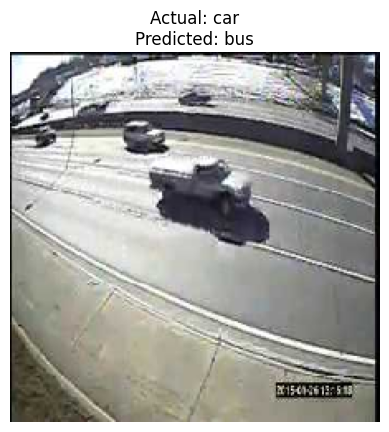

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step


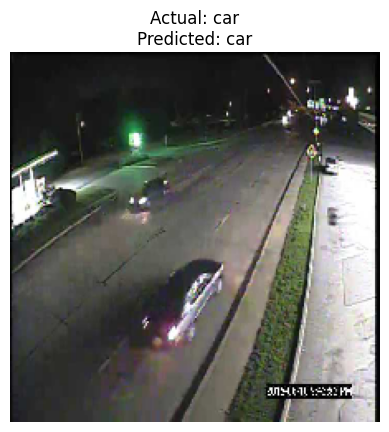

In [40]:
import os
import random
import matplotlib.pyplot as plt

train_dir = 'vehicle_dataset_reduced/train'
class_names = sorted(os.listdir(train_dir))

def predict_and_display_random_image(model, class_names, data_directory):
    # Select a random class
    random_class_name = random.choice(class_names)
    class_path = os.path.join(data_directory, random_class_name)

    # Select a random image from that class
    image_files = os.listdir(class_path)
    random_image_file = random.choice(image_files)
    image_path = os.path.join(class_path, random_image_file)

    # Load and preprocess the image
    img = tf.keras.preprocessing.image.load_img(image_path, target_size=(224, 224))
    myImgNpArray = tf.keras.preprocessing.image.img_to_array(img)
    # Apply VGG16 preprocessing (already defined in traingenerator)
    preprocessed_img = tf.keras.applications.vgg16.preprocess_input(myImgNpArray)
    myCompatibleImg = np.expand_dims(preprocessed_img, axis=0)

    # Make a prediction
    prediction_probabilities = model.predict(myCompatibleImg)
    predicted_class_index = np.argmax(prediction_probabilities)
    predicted_class_name = class_names[predicted_class_index]

    # Display the image and prediction
    plt.imshow(img)
    plt.title(f"Actual: {random_class_name}\nPredicted: {predicted_class_name}")
    plt.axis('off')
    plt.show()

# Predict and display for a couple of random images
for _ in range(2):
    predict_and_display_random_image(model, class_names, train_dir)

#Analysis Section

Some misclassifications occurred between visually similar categories such as trucks and cars, particularly in distant or low-resolution images. This indicates that while the model learned general vehicle features effectively, fine-grained class separation remains challenging due to viewpoint and scale variations.

#Conclusion

In this project, a vehicle classification model was developed using transfer learning with MobileNetV2. Initial experiments highlighted challenges such as underfitting and overfitting, which were resolved through proper model redesign and regularization. By freezing the backbone and later fine-tuning selected layers with a reduced learning rate, the model achieved approximately 75–76% validation accuracy with improved F1-score (~0.50). The results demonstrate effective generalization and practical application of transfer learning on a moderate-sized dataset. Overall, the project successfully illustrates the importance of controlled fine-tuning and model optimization in deep learning workflows.